# 06-1 에이전트 기초 · 도구와 ReAct

교안 `06-1_에이전트_기초_도구와_ReAct.html`과 같은 순서의 실습 노트북입니다.

## 0. 에이전트란 무엇인가

> **전제** 05까지 StateGraph · 조건 분기 · 체크포인터 · interrupt · 병렬 실행을 배웠습니다. 이번 단원은 그 위에 **LLM이 스스로 다음 행동을 고르는 그래프**를 올립니다.

### 05 RAG 그래프와 무엇이 다른가

|  | 05 실습 (고정 그래프) | 06 에이전트 |
|---|---|---|
| 다음에 무엇을 할지 | **사람(코드)**이 엣지로 정해 둠 | **LLM**이 매번 고름 |
| 검색 횟수 | 항상 1번 (또는 병렬 3개) | 필요한 만큼. 0번일 수도, 3번일 수도 |
| 도구 순서 | retrieve → draft 고정 | 질문에 따라 달라짐 (날씨만, 환율만, 둘 다) |
| 장점 | 예측 가능, 디버깅 쉬움 | 처음 보는 질문에도 대응 |
| 단점 | 질문 유형이 늘면 분기가 폭발 | 돌발 행동 · 무한 반복 · 비용 증가 → 06-2에서 막는다 |

> **선택 기준** 절차가 정해진 업무(승인 · 정산 · 정형 RAG)는 고정 그래프, 질문이 다양하고 필요한 도구 조합이 매번 다르면 에이전트. 실무에서는 둘을 섞습니다(고정 그래프 안의 한 노드가 에이전트).

### ReAct = Reasoning + Acting 반복

에이전트의 기본 형태는 ReAct입니다. LLM이 **생각하고(Reason)** → **도구를 고르고(Act)** → **결과를 보고(Observe)** → 다시 생각합니다. 도구가 더 필요 없다고 판단하면 최종 답을 냅니다.

### 대화 기록에 남는 메시지 4종

에이전트가 한 바퀴 돌면 `messages`에 아래 순서로 쌓입니다. 이 흐름을 읽을 줄 알면 에이전트의 모든 동작을 따라갈 수 있습니다.

| 순서 | 메시지 | 누가 만드나 | 내용 |
|---|---|---|---|
| 1 | `HumanMessage` | 사용자 | "부산 날씨 알려주고, 100달러는 원화로 얼마야?" |
| 2 | `AIMessage` + `tool_calls` | LLM | content는 비어 있고, "get_weather(city=부산), to_krw(amount=100, currency=USD)를 불러 줘"라는 **요청** |
| 3 | `ToolMessage` × 2 | 도구 실행 노드 | "흐림 20도", "100 USD = 138,000원". `tool_call_id`로 2번의 요청과 짝지어짐 |
| 4 | `AIMessage` | LLM | 도구 결과를 보고 쓴 최종 답. `tool_calls` 없음 → 끝 |

> **가장 중요한 한 줄** LLM은 도구를 **실행하지 않습니다**. "이 도구를 이 인자로 불러 달라"고 **요청(tool_calls)**만 합니다. 실행은 우리 코드(ToolNode)가 합니다. 그래서 위험한 도구는 실행 전에 막을 수 있습니다(06-2).

### 이 단원의 순서

1. **도구 만들기.** `@tool`로 함수를 도구로 바꾸고, LLM이 읽는 설명서(이름 · 설명 · 인자)를 확인한다.
2. **bind_tools와 tool_calls.** LLM에 도구 목록을 알려 주고, LLM이 돌려준 요청을 손으로 실행해 본다.
3. **직접 만드는 ReAct.** 2번을 StateGraph 루프로 자동화한다. `ToolNode`, `tools_condition`.
4. **create_agent.** 3번을 한 줄로. 실무 기본값.

## 1. 도구 만들기 · @tool

### 준비

In [1]:
!pip install -q langgraph langchain langchain-openai


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import os
os.environ["OPENAI_API_KEY"] = "sk-..."   # 본인 키

### 함수에 @tool을 붙이면 도구가 된다

In [2]:
from langchain.tools import tool

WEATHER = {"서울": "맑음 18도", "부산": "흐림 20도", "제주": "비 17도"}   # 가짜 날씨 데이터


@tool
def get_weather(city: str) -> str:
    """도시의 오늘 날씨를 알려준다. 날씨나 기온을 물으면 사용한다.

    Args:
        city: 도시 이름 (예: 서울, 부산, 제주)
    """
    return WEATHER.get(city, f"{city} 날씨 정보 없음")


print("name :", get_weather.name)
print("desc :", get_weather.description)
print("args :", get_weather.args)

name : get_weather
desc : 도시의 오늘 날씨를 알려준다. 날씨나 기온을 물으면 사용한다.

    Args:
        city: 도시 이름 (예: 서울, 부산, 제주)
args : {'city': {'title': 'City', 'type': 'string'}}


`@tool`은 함수를 LLM이 읽을 수 있는 **설명서**로 바꿉니다. LLM은 함수 코드를 보지 못하고 이 세 가지만 봅니다.

| 설명서 항목 | 어디서 오나 | LLM이 쓰는 용도 |
|---|---|---|
| `name` | 함수 이름 | 어떤 도구를 부를지 지목 |
| `description` | docstring | **언제** 이 도구를 써야 하는지 판단 |
| `args` | 타입 힌트 (`city: str`) | 인자를 어떤 형태로 채울지 |

### parse_docstring=True: 인자 설명까지 따로 넣기

위 출력을 보면 Args 설명이 description에 통째로 붙고, `args`에는 인자 설명이 없습니다. `parse_docstring=True`를 주면 Args 부분을 인자마다 나눠 넣습니다.

In [3]:
@tool(parse_docstring=True)
def get_weather(city: str) -> str:
    """도시의 오늘 날씨를 알려준다. 날씨나 기온을 물으면 사용한다.

    Args:
        city: 도시 이름 (예: 서울, 부산, 제주)
    """
    return WEATHER.get(city, f"{city} 날씨 정보 없음")


print("desc :", get_weather.description)
print("args :", get_weather.args)

desc : 도시의 오늘 날씨를 알려준다. 날씨나 기온을 물으면 사용한다.
args : {'city': {'description': '도시 이름 (예: 서울, 부산, 제주)', 'title': 'City', 'type': 'string'}}


> **왜 이게 중요한가** LLM은 `args`의 description을 보고 인자 값을 채웁니다. "도시 이름 (예: 서울, 부산, 제주)"가 있으면 "부산광역시"나 "Busan" 대신 "부산"을 넣을 확률이 올라갑니다. Args 형식(Google 스타일)을 지켜야 하며, 형식이 틀리면 에러가 납니다.

### 두 번째 도구: 계산은 LLM 말고 도구로

In [4]:
RATES = {"USD": 1380, "JPY": 9.2, "EUR": 1500}   # 고정 환율 (예시)


@tool(parse_docstring=True)
def to_krw(amount: float, currency: str) -> str:
    """외화 금액을 원화로 환산한다. 환율 계산이 필요하면 사용한다.

    Args:
        amount: 외화 금액 (예: 100)
        currency: 통화 코드. USD, JPY, EUR 중 하나
    """
    if currency not in RATES:
        return f"{currency}는 지원하지 않는 통화입니다. USD, JPY, EUR만 가능합니다."
    return f"{amount:g} {currency} = {amount * RATES[currency]:,.0f}원"

> **LLM에게 계산을 맡기지 않는 이유** LLM은 다음 단어를 예측할 뿐이라 큰 수 곱셈 · 날짜 계산 · 규정 조건 판단에서 그럴듯하게 틀립니다. 정답이 정해진 일은 코드(도구)로, LLM은 **무엇을 부를지 고르는 일**만 맡깁니다.

### 도구는 그냥 함수처럼 먼저 테스트한다

In [5]:
print(get_weather.invoke({"city": "부산"}))
print(to_krw.invoke({"amount": 100, "currency": "USD"}))
print(to_krw.invoke({"amount": 100, "currency": "CNY"}))

흐림 20도
100 USD = 138,000원
CNY는 지원하지 않는 통화입니다. USD, JPY, EUR만 가능합니다.


도구는 LLM 없이 `.invoke({인자: 값})`로 바로 실행됩니다. 에이전트에 넣기 전에 이렇게 따로 확인해 두면, 나중에 문제가 생겼을 때 "도구 문제인지 LLM 문제인지"를 나눌 수 있습니다.

### 좋은 도구의 4가지 조건

| 조건 | 나쁜 예 | 좋은 예 | 이유 |
|---|---|---|---|
| 설명에 **언제** 쓰는지 | `"""날씨"""` | "날씨나 기온을 물으면 사용한다" | LLM이 도구를 고르는 유일한 근거 |
| 인자는 적고 단순하게 | `query: dict` | `city: str` | 복잡할수록 LLM이 틀리게 채움 |
| 실패도 문장으로 반환 | `raise KeyError` | "CNY는 지원하지 않는 통화입니다" | LLM이 읽고 다르게 시도할 수 있음 (06-2) |
| 한 도구는 한 가지 일 | `do_everything()` | `get_weather`, `to_krw` | 선택이 명확해지고 테스트가 쉬움 |

In [14]:
from langchain.tools import tool
from langchain.agents import create_agent

@tool
def calculate_discount(price: int, rate: int) -> int:
    """상품 가격과 할인율(%)로 할인 후 금액을 계산한다."""
    return price * (100 - rate) // 100

@tool
def get_delivery_days(region: str) -> str:
    """지역별 예상 배송 기간을 알려준다."""
    return "3~5일" if region == "제주" else "1~3일"

agent = create_agent(
    model="openai:gpt-4.1-mini",
    tools=[calculate_discount, get_delivery_days]
)       

q="서울 배송기간과 할인율?"
result=agent.invoke({"messages": [{'role':'user', 'content': q}]})

result


{'messages': [HumanMessage(content='서울 배송기간과 할인율?', additional_kwargs={}, response_metadata={}, id='ff2f2b5d-3040-4059-b41b-20224e62e1b8'),
  AIMessage(content='배송 지역은 서울이 맞나요? 그리고 할인율을 알고 싶은 상품의 가격도 알려주시면 할인가를 계산해 드릴 수 있습니다.', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 32, 'prompt_tokens': 88, 'total_tokens': 120, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4.1-mini-2025-04-14', 'system_fingerprint': 'fp_438e5bbc62', 'id': 'chatcmpl-EjHRRFxEQ9I145wYLPV1ngP0gzB5j', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a1ce2e-76b1-72da-9aba-5d0f25bb5c06-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'

In [15]:
agent.get_graph()


Graph(nodes={'__start__': Node(id='__start__', name='__start__', data=RunnableCallable(tags=None, recurse=True, explode_args=False, func_accepts={}), metadata=None), 'model': Node(id='model', name='model', data=model_node(tags=None, recurse=True, explode_args=False, func_accepts={'runtime': ('N/A', <class 'inspect._empty'>)}), metadata=None), 'tools': Node(id='tools', name='tools', data=tools(tags=None, recurse=True, explode_args=False, func_accepts={'config': ('N/A', <class 'inspect._empty'>), 'runtime': ('N/A', <class 'inspect._empty'>)}, _tools_by_name={'calculate_discount': StructuredTool(name='calculate_discount', description='상품 가격과 할인율(%)로 할인 후 금액을 계산한다.', args_schema=<class 'langchain_core.utils.pydantic.calculate_discount'>, func=<function calculate_discount at 0x000002469913F920>), 'get_delivery_days': StructuredTool(name='get_delivery_days', description='지역별 예상 배송 기간을 알려준다.', args_schema=<class 'langchain_core.utils.pydantic.get_delivery_days'>, func=<function get_delivery_d

## 2. bind_tools와 tool_calls · 손으로 한 바퀴

에이전트 루프를 만들기 전에, 한 바퀴를 **손으로** 돌려 봅니다. 이 과정이 곧 ToolNode와 create_agent가 자동으로 해 주는 일입니다.

### ① LLM에 도구 목록 알려 주기

In [16]:
from langchain.chat_models import init_chat_model
from langchain_core.messages import HumanMessage

llm = init_chat_model("openai:gpt-4o-mini", temperature=0)
llm_tools = llm.bind_tools([get_weather, to_krw])   # 도구 설명서를 LLM 요청에 함께 보냄

`bind_tools`는 LLM을 바꾸지 않습니다. 매 요청에 "너는 이런 도구들을 쓸 수 있어"라는 설명서(JSON 스키마)를 붙여 보내는 **새 LLM 객체**를 돌려줍니다.

### ② 질문하면 LLM은 답 대신 요청을 돌려준다

In [17]:
question = HumanMessage("부산 날씨 알려주고, 100달러는 원화로 얼마야?")
ai = llm_tools.invoke([question])

print("content   :", repr(ai.content))
for tc in ai.tool_calls:
    print("tool_call :", tc)

content   : ''
tool_call : {'name': 'get_weather', 'args': {'city': '부산'}, 'id': 'call_9uRgzScLA8dfTe5VeTYcJVez', 'type': 'tool_call'}
tool_call : {'name': 'to_krw', 'args': {'amount': 100, 'currency': 'USD'}, 'id': 'call_1YzLt6iKyKDpYUQrUKNFUcqw', 'type': 'tool_call'}


1. **content가 비어 있다.** 아직 답할 정보가 없으니 말 대신 요청만 했습니다.
2. **tool_calls가 두 개.** 질문에 필요한 일이 둘이라 **한 번에 두 도구**를 요청했습니다(병렬 도구 호출).
3. **id가 붙어 있다.** 나중에 결과를 돌려줄 때 "어느 요청의 결과인지" 짝짓는 번호입니다.

### ③ 요청을 우리가 실행하고 ToolMessage로 돌려준다

In [18]:
tools_by_name = {t.name: t for t in [get_weather, to_krw]}
messages = [question, ai]

for tc in ai.tool_calls:
    tool_msg = tools_by_name[tc["name"]].invoke(tc)    # tool_call을 통째로 넣으면 ToolMessage가 나온다
    print(type(tool_msg).__name__, tool_msg.tool_call_id[:8], "→", tool_msg.content)
    messages.append(tool_msg)

ToolMessage call_9uR → 흐림 20도
ToolMessage call_1Yz → 100 USD = 138,000원


> **tool.invoke(tc)의 비밀** 인자 dict(`{"city": "부산"}`) 대신 tool_call 전체(`tc`)를 넣으면, 결과를 `ToolMessage`로 감싸고 `tool_call_id`까지 채워 줍니다. ToolNode가 내부에서 하는 일이 바로 이것입니다.

### ④ 결과를 붙여 다시 물으면 최종 답

In [19]:
final = llm_tools.invoke(messages)
print("tool_calls:", final.tool_calls)
print(final.content)

tool_calls: []
부산의 오늘 날씨는 흐림이며, 기온은 20도입니다. 

또한, 100달러는 138,000원입니다.


이번에는 `tool_calls`가 비어 있습니다. LLM이 "더 부를 도구가 없다"고 판단했다는 뜻이고, 이것이 루프를 끝내는 신호가 됩니다.

### 도구가 필요 없는 질문

In [20]:
ai2 = llm_tools.invoke([HumanMessage("안녕? 너는 뭘 할 수 있어?")])
print("tool_calls:", ai2.tool_calls)
print(ai2.content)

tool_calls: []
안녕하세요! 저는 다양한 정보를 제공하고, 질문에 답변하며, 여러 가지 작업을 도와드릴 수 있습니다. 예를 들어:

1. 날씨 정보 제공: 특정 도시의 현재 날씨를 알려드릴 수 있습니다.
2. 환율 계산: 외화 금액을 원화로 환산할 수 있습니다.
3. 일반적인 질문에 대한 답변: 역사, 과학, 문화 등 다양한 주제에 대해 질문하실 수 있습니다.

무엇을 도와드릴까요?


도구를 쥐여 줬다고 항상 쓰는 것이 아닙니다. 쓸지 말지도 LLM이 고릅니다.

> **짝 규칙** `tool_calls`가 있는 AIMessage 뒤에는 **id마다** ToolMessage가 있어야 합니다. 하나라도 빠진 채 LLM을 다시 부르면 OpenAI · Anthropic API가 400 에러를 냅니다. 05의 "거부할 때도 ToolMessage를 넣는다"가 이 규칙 때문이었습니다.

## 3. 직접 만드는 ReAct 그래프

탭 2에서 손으로 한 "LLM 호출 → 도구 실행 → 다시 LLM"을 그래프 루프로 바꿉니다. 노드 두 개, 조건 엣지 하나면 됩니다.

| 손으로 한 일 (탭 2) | 그래프에서 | 누가 |
|---|---|---|
| `llm_tools.invoke(messages)` | agent 노드 | 직접 작성 |
| `for tc in ai.tool_calls: tool.invoke(tc)` | tools 노드 | `ToolNode` (내장) |
| "tool_calls가 있으면 실행, 없으면 끝" | 조건 엣지 | `tools_condition` (내장) |
| `messages.append(...)` | State 갱신 | `MessagesState`의 add_messages 리듀서 |

### agent 노드

In [23]:
from langgraph.graph import StateGraph, MessagesState, START, END
from langgraph.prebuilt import ToolNode, tools_condition
from langchain_core.messages import SystemMessage

tools = [get_weather, to_krw]
llm_tools = llm.bind_tools(tools)

SYSTEM = SystemMessage("너는 여행 비서다. 날씨와 환율은 반드시 도구로 확인하고, 한국어로 짧게 답한다.")


# agent: 지금까지의 대화를 보고 "도구 요청" 또는 "최종 답"을 만든다
def agent(state: MessagesState):
    response = llm_tools.invoke([SYSTEM] + state["messages"])
    return {"messages": [response]}

> **SYSTEM을 State에 넣지 않는 이유** 매 호출 앞에만 붙이고 return하지 않습니다. State에 넣으면 대화 기록에 시스템 지시가 계속 쌓이고, 체크포인터를 쓰면 저장까지 됩니다. 04의 "실행 설정은 State 밖에"와 같은 원리입니다.

### 조립: agent ⇄ tools 루프

In [24]:
g = StateGraph(MessagesState)
g.add_node("agent", agent)
g.add_node("tools", ToolNode(tools))            # tool_calls를 실행해 ToolMessage를 돌려주는 내장 노드

g.add_edge(START, "agent")
g.add_conditional_edges("agent", tools_condition)   # tool_calls 있으면 "tools", 없으면 END
g.add_edge("tools", "agent")                    # 도구 결과를 들고 다시 agent로 → 루프

react = g.compile()
print(list(react.get_graph().nodes))

['__start__', 'agent', 'tools', '__end__']


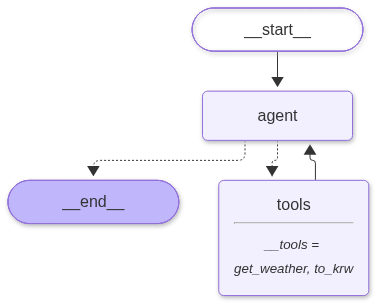

In [25]:
react

`tools_condition`은 아래 함수와 같습니다. 직접 써도 되고, 조건을 더 넣고 싶으면(06-2 승인 단계 등) 직접 씁니다.

> **노드 이름은 "tools"로** `tools_condition`은 문자열 `"tools"`를 돌려줍니다. 도구 노드 이름을 다르게 지으면(예: `"action"`) 연결할 곳을 못 찾습니다. 다른 이름을 쓰려면 위의 `route`처럼 직접 작성합니다.

### 실행하고 메시지 흐름 읽기

In [ ]:
r = react.invoke({"messages": [("user", "제주 날씨랑 50000엔은 원화로 얼마인지 알려줘")]})

for m in r["messages"]:
    내용 = m.content or [f"{tc['name']}({tc['args']})" for tc in m.tool_calls]
    print(f"{type(m).__name__:>13} | {내용}")

### stream으로 루프가 도는 모습 보기

In [ ]:
for chunk in react.stream({"messages": [("user", "서울 날씨 알려줘")]}, stream_mode="updates"):
    for node, update in chunk.items():
        m = update["messages"][-1]
        print(f"[{node}]", m.content or f"도구 요청 → {m.tool_calls[0]['name']}")

1. **agent가 두 번 실행됐다.** 한 번은 요청, 한 번은 최종 답. 도구가 필요한 질문은 최소 두 번 LLM을 부릅니다(비용 2배).
2. **tools는 한 번.** LLM이 한 번에 요청한 도구들은 tools 노드 한 번에 모두 실행됩니다.
3. **끝나는 조건은 LLM이 정한다.** 그래서 LLM이 계속 도구를 부르면 끝나지 않을 수 있습니다 → 06-2 안전장치.

## 4. create_agent로 한 줄

탭 3에서 직접 조립한 ReAct 그래프를 LangChain이 미리 만들어 둔 것이 `create_agent`입니다.

In [ ]:
from langchain.agents import create_agent

agent = create_agent(
    model=llm,                    # 또는 "openai:gpt-4o-mini" 문자열
    tools=tools,
    system_prompt="너는 여행 비서다. 날씨와 환율은 반드시 도구로 확인하고, 한국어로 짧게 답한다.",
)
print(list(agent.get_graph().nodes))

노드 이름만 `agent` → `model`로 다를 뿐 구조는 같습니다. `bind_tools`, 시스템 프롬프트, 조건 엣지, 루프를 모두 안에서 해 줍니다.

In [ ]:
for chunk in agent.stream({"messages": [("user", "부산 날씨랑 30유로는 얼마야?")]}, stream_mode="updates"):
    for node, update in chunk.items():
        m = update["messages"][-1]
        print(f"[{node}]", m.content or [tc["name"] for tc in m.tool_calls])

탭 3과 달리 `[tools]`가 **두 줄**입니다. create_agent는 도구 요청마다 따로 실행 작업을 만들어(05의 Send처럼) **동시에** 돌립니다. 그래서 결과 순서는 실행마다 바뀔 수 있습니다.

### 직접 만들기 vs create_agent

|  | StateGraph 직접 (탭 3) | create_agent |
|---|---|---|
| 코드 양 | 15줄 안팎 | 5줄 |
| 노드 이름 | 마음대로 (`agent`, `tools`) | `model`, `tools` 고정 |
| 중간에 노드 끼우기 | 자유 (검사 · 승인 · 요약 노드) | 미들웨어로 (06-2) |
| State 확장 | `class S(MessagesState)`에 키 추가 | `state_schema` 또는 미들웨어 |
| 언제 | 흐름을 세밀하게 바꿔야 할 때, 학습용 | **대부분의 실무**. 먼저 이걸로 시작 |

> **배우는 순서와 쓰는 순서는 반대** 원리를 알려고 직접 만들어 봤고, 실무에서는 create_agent로 시작해 부족할 때만 StateGraph로 내려갑니다. 06-2의 메모리 · 에러 · 승인 · 가드레일도 둘 다 보여 줍니다.

### create_agent가 돌려주는 것도 그래프다

In [ ]:
r = agent.invoke({"messages": [("user", "도쿄 날씨 알려줘")]})
print(r["messages"][-1].content)

`invoke` · `stream` · `get_state` · 체크포인터 · `interrupt`가 모두 그대로 동작합니다. 지금까지 배운 LangGraph 지식이 그대로 쓰입니다. 도구가 "도쿄 날씨 정보 없음"을 **문장으로** 돌려준 덕분에 LLM이 사용자에게 자연스럽게 안내했습니다(탭 1의 "실패도 문장으로").

## 5. 정리

| 개념 | 한 줄 | 코드 |
|---|---|---|
| 도구 | LLM이 읽는 설명서가 붙은 함수 | `@tool(parse_docstring=True)` |
| bind_tools | 요청마다 도구 설명서를 붙여 보냄 | `llm.bind_tools(tools)` |
| tool_calls | LLM의 실행 **요청**. 실행은 우리 코드가 | `ai.tool_calls` |
| ToolMessage | 도구 결과. `tool_call_id`로 요청과 짝 | `tool.invoke(tc)` |
| ToolNode | tool_calls를 모두 실행하는 내장 노드 | `ToolNode(tools)` |
| tools_condition | tool_calls 있으면 tools, 없으면 END | `add_conditional_edges("agent", tools_condition)` |
| create_agent | 위 전부를 한 줄로 | `create_agent(model, tools, system_prompt)` |

> **LLM은 고르고, 코드는 실행한다.** 에이전트는 "LLM이 다음 행동을 고르는 루프"이고, 실행 · 계산 · 검증은 도구와 그래프가 맡는다.

### 실행으로 확인한 주의점

| 주의점 | 확인 결과 |
|---|---|
| Args 설명이 args에 안 들어감 | `@tool` 기본값은 docstring 전체를 description에 넣음. 인자별 설명은 `parse_docstring=True` |
| 도구 노드 이름 | `tools_condition`은 "tools"로만 보냄 |
| 도구 안에서 예외가 나면 | ToolNode · create_agent 모두 **기본값으로는 그래프가 멈춤** (인자 타입 오류만 자동으로 ToolMessage). → 06-2 탭 1 |

> **다음** 06-2에서 메모리 · 에러 처리 · 무한 반복 방지 · 사람 승인 · 가드레일을 붙여 "운영 가능한" 에이전트로 만듭니다.